## Hierarchial methods

In [1]:
import numpy as np
import pandas as pd

import matplotlib.pyplot as plt
from pylab import rcParams
import seaborn as sns

import sklearn
import sklearn.metrics as sm

In [2]:
from sklearn.cluster import AgglomerativeClustering

import scipy
from scipy.cluster.hierarchy import dendrogram, linkage, fcluster, cophenet
from scipy.spatial.distance import pdist

In [3]:
np.set_printoptions(precision=4, suppress=True)
plt.figure(figsize=(10, 3))
%matplotlib inline
sns.set_style("whitegrid")

In [5]:
address = "/Users/Russell/workspace/github.com/python-for-data-science-and-machine-learning-essential-training-part-2/data/mtcars.csv"

cars = pd.read_csv(address)

cars.columns = ["car_names","mpg","cyl","disp","hp","drat","wt","qsec","vs","am","gear","carb"]

X = cars[["mpg","disp","hp","wt"]].values

y = cars.iloc[:, 9].values

### Using scipy to generate dendrograms

In [6]:
Z = linkage(X, method='ward')

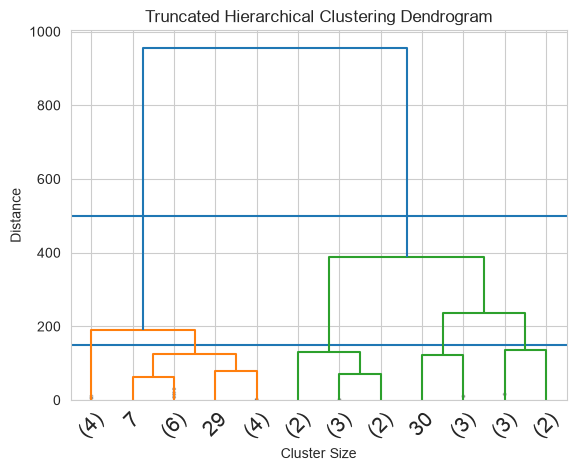

In [8]:
dendrogram(Z, truncate_mode='lastp', p=12, leaf_rotation=45., leaf_font_size=15., show_contracted=True)

plt.title('Truncated Hierarchical Clustering Dendrogram')
plt.xlabel('Cluster Size')
plt.ylabel('Distance')
plt.show()

plt.axhline(y=500, color='r', linestyle='--')
plt.axhline(y=150, color='g', linestyle='--')

### Generating hierarchical clusters

In [11]:
k = 2

Hclustering = AgglomerativeClustering(n_clusters=k, metric='euclidean', linkage='ward').fit(X)

sm.accuracy_score(y, Hclustering.labels_)

0.78125

In [12]:
k = 2

Hclustering = AgglomerativeClustering(n_clusters=k, metric='euclidean', linkage='average').fit(X)

sm.accuracy_score(y, Hclustering.labels_)

0.78125

In [13]:
k = 2

Hclustering = AgglomerativeClustering(n_clusters=k, metric='manhattan', linkage='average').fit(X)

sm.accuracy_score(y, Hclustering.labels_)

0.71875